In [38]:
from sklearn.datasets import load_iris
from sklearn.datasets import load_diabetes
from sklearn.datasets import load_breast_cancer
from sklearn.datasets import load_wine
from sklearn.datasets import fetch_california_housing

from sklearn.metrics import r2_score as r2
from sklearn.metrics import mean_absolute_error as mae
from sklearn.metrics import root_mean_squared_error as rmse
from sklearn.metrics import mean_absolute_percentage_error as mape

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import cross_validate

from sklearn.metrics import accuracy_score

from sklearn.metrics import precision_recall_fscore_support as supers

from sklearn.svm import SVR
from sklearn.svm import SVC
from seaborn import kdeplot
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt;
import warnings as yap; yap.simplefilter('ignore')

#1 Загрузить встроенный в библиотеку sklearn датасет “Ирисы”. Несколькими способами, в том числе графическим, убедиться в отсутствии пропущенных значений.

In [7]:
df1 = load_iris(as_frame=True).frame

print(df1.isna().sum())
# Графически забыл, открою колаб
for

sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
dtype: int64


#2 Загрузить встроенный в библиотеку sklearn датасет “Диабет”. Визуализировать распределение четырех любых признаков, входящих в датасет. Сделать содержательные выводы по полученным данным.

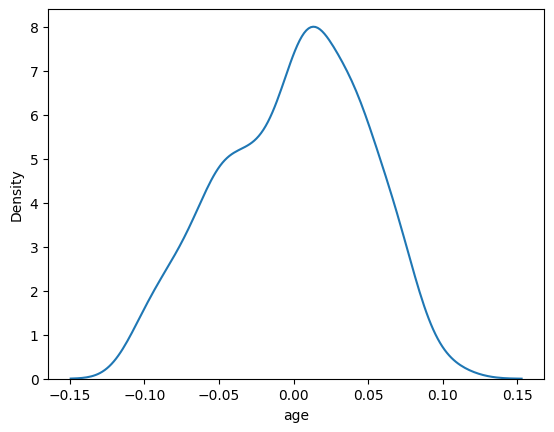

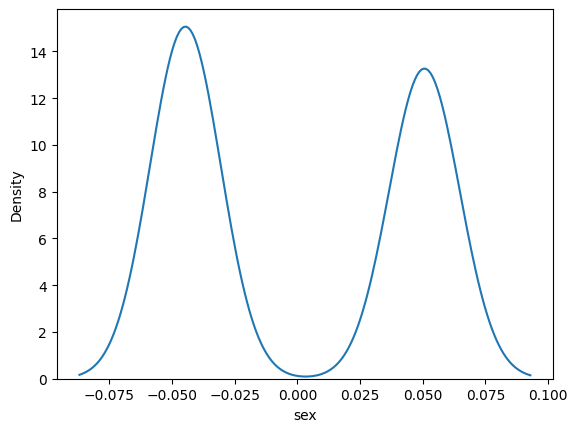

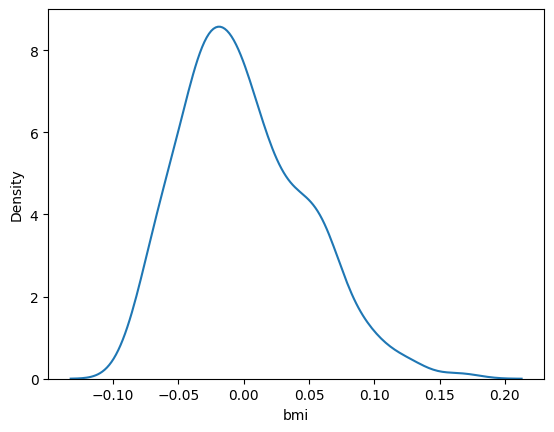

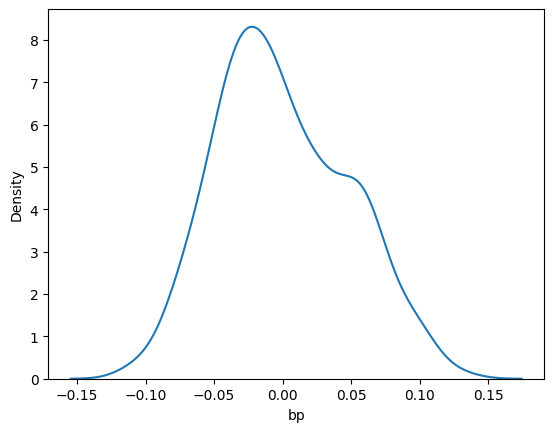

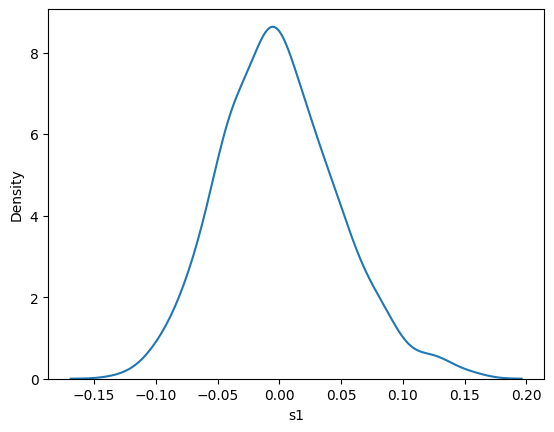

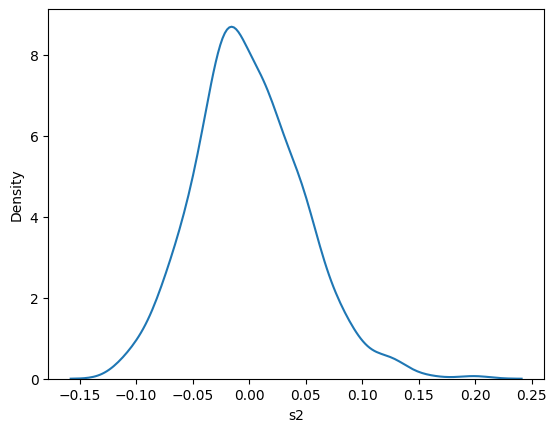

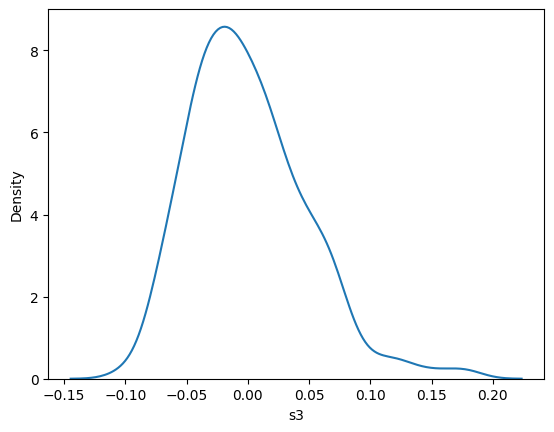

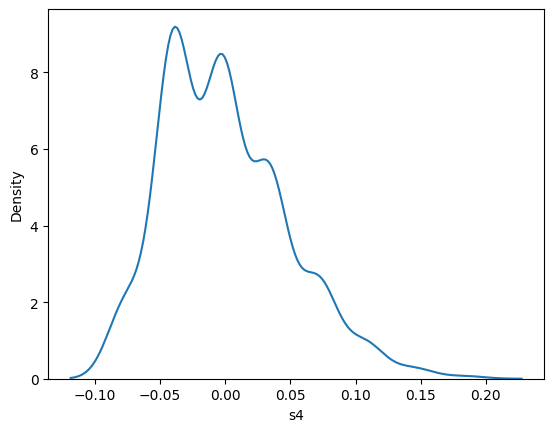

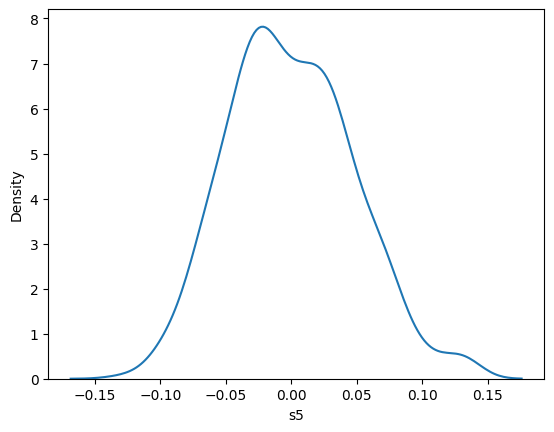

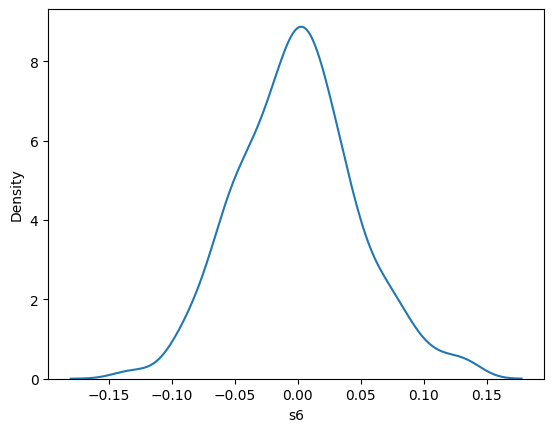

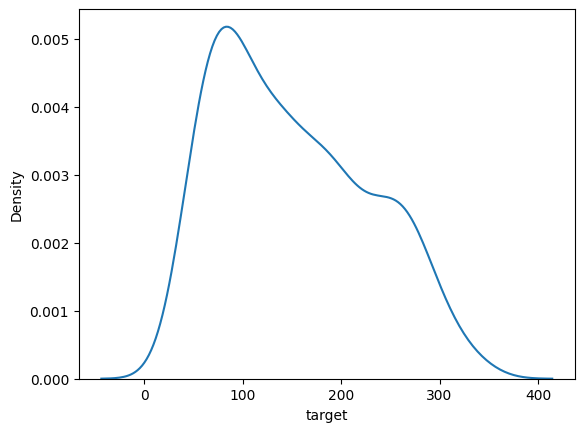

In [10]:
df2 = load_diabetes(as_frame=True).frame
for i in df2:
  kdeplot(df2[i]);plt.show()

#3 Загрузить встроенный в библиотеку sklearn датасет “Рак груди”. Построить модель бинарной классификации любым методом. Вывести несколько первых теоретических и эмпирических значений целевой переменной. Сделать выводы по полученным результатам.

In [37]:
df3 = load_breast_cancer(as_frame=True).frame
display(df3.head())
m = LogisticRegression()
x = df3.drop('target',axis=1)
y = df3[['target']]
x_train, x_test, y_train, y_test = train_test_split( x, y, test_size=0.33, random_state=42)
m.fit(x_train,y_train)
#print(y.value_counts())
#print(m.coef_)
print(m.score(x_test,y_test))
print(m.predict(x_test)[:5])
print(y_test[:5].values.reshape(-1))

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


0.9574468085106383
[1 0 0 1 1]
[1 0 0 1 1]


#4 Загрузить встроенный в библиотеку sklearn датасет “Вина”. Построить линейную модель обучения с учителем, вывести и проинтерпретировать коэффициенты линейной модели. Коэффициенты должны выводиться вместе с названием соответствующего признака.



In [43]:
df4 = load_wine(as_frame=True).frame

m = LogisticRegression()
SC = StandardScaler()
x = df4.drop('target',axis=1)
y = df4[['target']]
x_train, x_test, y_train, y_test = train_test_split( x, y, test_size=0.33, random_state=42)
x_train = SC.fit_transform(x_train)
x_test = SC.transform(x_test)
m.fit(x_train,y_train)
print(m.score(x_test,y_test))
display(df4.head())
print(y.value_counts())
print(m.coef_)
# Почему коэффициентов 3 массива??
print(*zip(x.columns,m.coef_[0]),sep='\n')

0.9830508474576272


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


target
1         71
0         59
2         48
Name: count, dtype: int64
[[ 0.7846578   0.10957226  0.44853551 -0.83518582  0.04718734  0.35274966
   0.51814201 -0.04479513  0.20179049  0.16126216  0.07559923  0.60108719
   0.89863265]
 [-1.02544026 -0.29377471 -0.82286238  0.71297325 -0.10904978 -0.16437731
   0.34356055  0.08018068  0.37340207 -0.81888773  0.7279605   0.12620666
  -0.9629896 ]
 [ 0.24078246  0.18420245  0.37432687  0.12221256  0.06186244 -0.18837234
  -0.86170256 -0.03538555 -0.57519256  0.65762557 -0.80355973 -0.72729385
   0.06435695]]
('alcohol', np.float64(0.7846577989021976))
('malic_acid', np.float64(0.10957225879045429))
('ash', np.float64(0.44853550895988076))
('alcalinity_of_ash', np.float64(-0.8351858186057114))
('magnesium', np.float64(0.047187344746700596))
('total_phenols', np.float64(0.35274965535244196))
('flavanoids', np.float64(0.5181420086787826))
('nonflavanoid_phenols', np.float64(-0.044795126897143406))
('proanthocyanins', np.float64(0.20179048982

#5 Загрузить встроенный в библиотеку sklearn датасет “Калифорния”. Построить модель регрессии любым методом. Оптимизировать гиперпараметры модели при помощи поиска по сетке. Сделать выводы.

In [3]:
df5 = fetch_california_housing(as_frame=True).frame
display(df5.head())
m = LinearRegression()
SC = StandardScaler()
x = df5.drop('MedHouseVal',axis=1)
y = df5[['MedHouseVal']]
x_train, x_test, y_train, y_test = train_test_split( x, y, test_size=0.33, random_state=42)
x_train = SC.fit_transform(x_train)
x_test = SC.transform(x_test)
m.fit(x_train,y_train)
print(m.score(x_test,y_test))

m = SVR()
gs = GridSearchCV(m, {'kernel':['linear', 'poly', 'rbf', 'sigmoid']})
gs.fit(x_train,y_train)
sorted(gs.cv_results_.keys())

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


0.5970494128783952


KeyboardInterrupt: 

#6 Загрузить встроенный в библиотеку sklearn датасет “Ирисы”. Построить модель множественной классификации любым методом. Оценить ее эффективность при помощи кросс-валидации. Сделать выводы.

In [9]:
m = LogisticRegression()

df1 = load_iris(as_frame=True).frame
display(df1.head())
x = df1.drop('target',axis=1)
y = df1[['target']]


cross_validate(m,x,y)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


{'fit_time': array([0.03169584, 0.15191483, 0.06723046, 0.03888774, 0.10142064]),
 'score_time': array([0.01182318, 0.00691581, 0.0091455 , 0.00516295, 0.01357222]),
 'test_score': array([0.96666667, 1.        , 0.93333333, 0.96666667, 1.        ])}

#7 Загрузить встроенный в библиотеку sklearn датасет “Диабет”. Построить модель регрессии по методу опорных векторов с линейным ядром. Оценить ее эффективность по метрикам  r2, mae, rmse, mape. Сделать выводы о применимости модели.

In [23]:
df2 = load_diabetes(as_frame=True).frame

m = SVR(kernel='linear')
SC = StandardScaler()
x = df2.drop('target',axis=1)
y = df2[['target']]
x_train, x_test, y_train, y_test = train_test_split( x, y, test_size=0.33, random_state=42)
x_train = SC.fit_transform(x_train)
x_test = SC.transform(x_test)
m.fit(x_train,y_train)
print(m.score(x_test,y_test))

#r2_score as r2
#mean_absolute_error as mae
#root_mean_squared_error as rmse
#mean_absolute_percentage_error as mape
display(df2.describe())
display(r2(y_test,m.predict(x_test)))
display(mae(y_test,m.predict(x_test)))
display(rmse(y_test,m.predict(x_test)))
display(mape(y_test,m.predict(x_test)))
# Плохо применима, mae и rmse похожи на стандартное отклонение.

0.5016389783474011


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
count,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,442.000000
mean,-2.511817e-19,1.230790e-17,-2.245564e-16,-4.797570e-17,-1.381499e-17,3.918434e-17,-5.777179e-18,-9.042540e-18,9.293722e-17,1.130318e-17,152.133484
std,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,77.093005
min,-1.072256e-01,-4.464164e-02,-9.027530e-02,-1.123988e-01,-1.267807e-01,-1.156131e-01,-1.023071e-01,-7.639450e-02,-1.260971e-01,-1.377672e-01,25.000000
25%,-3.729927e-02,-4.464164e-02,-3.422907e-02,-3.665608e-02,-3.424784e-02,-3.035840e-02,-3.511716e-02,-3.949338e-02,-3.324559e-02,-3.317903e-02,87.000000
50%,5.383060e-03,-4.464164e-02,-7.283766e-03,-5.670422e-03,-4.320866e-03,-3.819065e-03,-6.584468e-03,-2.592262e-03,-1.947171e-03,-1.077698e-03,140.500000
75%,3.807591e-02,5.068012e-02,3.124802e-02,3.564379e-02,2.835801e-02,2.984439e-02,2.931150e-02,3.430886e-02,3.243232e-02,2.791705e-02,211.500000
max,1.107267e-01,5.068012e-02,1.705552e-01,1.320436e-01,1.539137e-01,1.987880e-01,1.811791e-01,1.852344e-01,1.335973e-01,1.356118e-01,346.000000


0.5016389783474011

42.30819704671922

53.555552494360946

0.34690539721357894

#8 Загрузить встроенный в библиотеку sklearn датасет “Рак груди”. Построить модель бинарной линейной классификации. Задать значения аргументов конструктора объекта модели, отличающиеся от значений по умолчанию. Пояснить смысл каждого аргумента.

In [29]:
df3 = load_breast_cancer(as_frame=True).frame
display(df3.head())
m = LogisticRegression(penalty='elasticnet',solver='saga',l1_ratio = 0.2)
x = df3.drop('target',axis=1)
y = df3[['target']]
x_train, x_test, y_train, y_test = train_test_split( x, y, test_size=0.33, random_state=42)
m.fit(x_train,y_train)
#print(y.value_counts())
#print(m.coef_)
print(m.score(x_test,y_test))
print(m.predict(x_test)[:5])
print(y_test[:5].values.reshape(-1))

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


0.9574468085106383
[0 0 0 1 1]
[1 0 0 1 1]


# 9 Загрузить встроенный в библиотеку sklearn датасет “Вина”. Построить модель множественной классификации по методу опорных векторов с полиномиальным ядром. Оценить ее эффективность по метрикам accuracy, precision, recall, f1. Сделать выводы о применимости модели.

In [43]:
df4 = load_wine(as_frame=True).frame

m = SVC(kernel='poly',degree=3)
SC = StandardScaler()
x = df4.drop('target',axis=1)
y = df4[['target']]
x_train, x_test, y_train, y_test = train_test_split( x, y, test_size=0.33, random_state=42)
x_train = SC.fit_transform(x_train)
x_test = SC.transform(x_test)
m.fit(x_train,y_train)
print(m.score(x_test,y_test))


'''

precision
float (if average is not None) or array of float, shape = [n_unique_labels]
Precision score.

recall
float (if average is not None) or array of float, shape = [n_unique_labels]
Recall score.

fbeta_score
float (if average is not None) or array of float, shape = [n_unique_labels]
F-beta score.

support
None (if average is not None) or array of int, shape = [n_unique_labels]
The number of occurrences of each label in y_true.

'''

print(*zip('accuracy, precision, recall, f1'.split(','),[m.score(x_test,y_test)]+list(supers(y_test,m.predict(x_test), average='macro')[:3])),sep='\n')

0.9661016949152542
('accuracy', 0.9661016949152542)
(' precision', 0.9743589743589745)
(' recall', 0.9611111111111111)
(' f1', 0.966625405246095)


# 10 Загрузить встроенный в библиотеку sklearn датасет “Калифорния”. Построить модель регрессии с регуляризацией. Задать значения аргументов конструктора объекта модели, отличающиеся от значений по умолчанию. Пояснить смысл каждого аргумента.